## Loading Data:
I decided to add year when loading each data file so it's easier to split the data chronologically and for the audit. I will not be using CO as it's an output of the gas turbine rather than a feature that can be used to help predict NOx values. Year and CO won't be used as features as seen by my Features list which exclude both.

In [1]:
import sys, platform
print(platform.python_version())
print(sys.executable)   # this should point inside your .venv

FEATURES = ["AT","AP","AH","AFDP","GTEP","TIT","TAT","TEY","CDP"]
TARGET = "NOX"
assert "year" not in FEATURES and "CO" not in FEATURES

3.14.7
C:\Users\omars\Documents\GitHub\CT4101-ML\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("..") / "data"

frames = []
for y in range(2011, 2016):
    d = pd.read_csv(DATA_DIR / f"gt_{y}.csv")
    d["year"] = y
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
print(df.shape)
print(df.groupby("year").size())

(36733, 12)
year
2011    7411
2012    7628
2013    7152
2014    7158
2015    7384
dtype: int64


## Data Audit:


In [3]:
# Shape, types & missing
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(36733, 12)
AT      float64
AP      float64
AH      float64
AFDP    float64
GTEP    float64
TIT     float64
TAT     float64
TEY     float64
CDP     float64
CO      float64
NOX     float64
year      int64
dtype: object
AT      0
AP      0
AH      0
AFDP    0
GTEP    0
TIT     0
TAT     0
TEY     0
CDP     0
CO      0
NOX     0
year    0
dtype: int64


Shape is 36,733 rows and 12 columns, 1 being the year we added. The rest are the features e.g. "AT","AP"& "AH" and then CO and NOx. All sensor values are continous float64, so we don't need encoding and only year is int64. There are no missing values so we don't need to remove any rows or do imputation. However not every hour in every year is recorded, we don't know how big the gaps between each hour is only that is chronological.

In [4]:
# Duplicates
print(df.duplicated().sum())
print(df[df.duplicated(keep=False)].groupby("year").size())

7
year
2014    9
dtype: int64


7 duplicates total in the dataset, it says 9 in 2014 as it includes the originals and the repeats, so 2 original rows and 7 repeats. I will keep these values for 2 reasons. 1. As the repeats are in the test set and won't affect the training. 2. The 2014 data has 7158 rows and 2015 data has 7384 rows, so 14542 test rows total, 7/14542 = 0.00048, 0.00048% of the test set has repeated data which is negligible.

min: 25.905
max: 119.91
mean: 65.29306726921297
median: 63.849
skew: 1.0267788505165132
rows below 40: 24
year
2011    67.575392
2012    68.788965
2013    70.007899
2014    60.066886
2015    59.890509
Name: NOX, dtype: float64


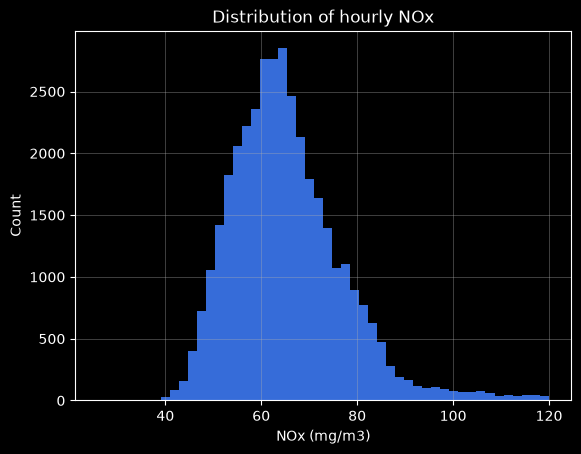

In [5]:
# Target distribution
import matplotlib.pyplot as plt

target = df[TARGET]

print("min:", target.min())
print("max:", target.max())
print("mean:", target.mean())
print("median:", target.median())
print("skew:", target.skew())
print("rows below 40:", (target < 40).sum())
print(target.groupby(df["year"]).mean())

target.hist(bins=50)
plt.xlabel("NOx (mg/m3)"); plt.ylabel("Count"); plt.title("Distribution of hourly NOx"); plt.show()

NOx peak is around 60-65 mg/m3, it has a long right tail that reaches as far as 120 mg/m3, its range is from 25.905-119.91, it has a mean of 65.29 and has a median of 63.85. Looking at the histogram and the skew value we can see that there is a moderate right skew. Since it's only a moderate skew where the tail only affects a small amount of rows and I plan on using random forest and gradient boosting which don't need a symmetric distribution, I won't be transforming NOx into Log Nox. However, it may be useful for a linear model and may do so on the validation folds but not on the test set. The skew is another reason why I will be using MAE as my main metric instead of RMSE since it's less affected by a few large values. The mean will also be pulled right due to this skew. Lastly, there is a drift in mean NOx values for each year, 2011-2013 has a range of 67.58-70.01 but 2014-2015 is about 60, with 2014 having a mean of 60.07 & 2015 a mean of 59.89, the mean NOx for the last 2 years is lower than the first 3 years. Due to this drift I expect a worse performance on the test years than in the cross validation.

max: 550.61
share of rows >= 549: 0.674243867911687


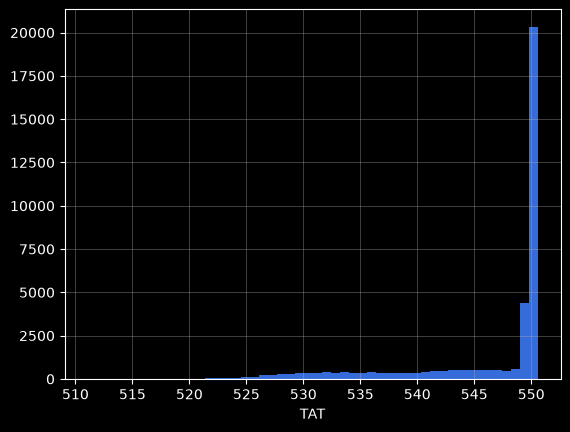

AT         1
AP       612
AH       132
AFDP     557
GTEP       7
TIT      315
TAT     4955
TEY       33
CDP       10
CO      2655
NOX      936
dtype: int64

In [6]:
# Outliers (1.5 x IQR rule)

tat = df["TAT"]
print("max:", tat.max())
print("share of rows >= 549:", (tat >= 549).mean())
tat.hist(bins=50); plt.xlabel("TAT"); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum()

df.drop(columns="year").apply(iqr_outliers)

I've used the 1.5 X IQR rule as it doesn't require a normal distribution. Most columns have few flagged values e.g. CDP 10, TEY 33 & AH 132. There are large counts e.g. TAT 4955, CO 2655 & NOx 936, however for NOx 936/36733 = 2.55% which is a small amount of the total number of NOx values in the dataset. TAT's count can be explained by looking at its histogram, it has a cap of around 550 and most of its values sit against this cap, 67% of TAT values are 549 or above, this makes the IQR small and the rule only flags the values distributed on the left tail. Due to this, TAT may be less informative compared to other features. I will not remove these values as they don't seem to be errors with the sensors but real world conditions and I have no proof that they are wrong. In addition, MAE and the tree based models are less sensitive to them. However, linear regression may be sensitive to them.  CO is an output value that I'm not predicting and not a feature so it's count doesn't matter to the models.

## Preprocessing pipeline & explanation of train/test split

In [7]:
# train/test split

train = df[df.year <= 2013]
test  = df[df.year >= 2014]
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]
print(len(train), len(test))

22191 14542


In [8]:
#forward-chaining CV folds

folds = [((2011,), 2012), ((2011, 2012), 2013)]   # (train years, validation year)
for tr_years, va_year in folds:
    n_tr = df.year.isin(tr_years).sum()
    n_va = (df.year == va_year).sum()
    print(tr_years, "->", va_year, n_tr, n_va)

(2011,) -> 2012 7411 7628
(2011, 2012) -> 2013 15039 7152


The train set is 2011-2013 (22,191 rows) and test set is 2014-2015 (14,542 rows), I'll be using this split as it's instructed by the dataset's UCI page. This split is chronological as a random one would put near identical neighbouring hours in both sets that would inflate scores and hide the NOx drift. I'll be using 2 forward chaining folds within the training years, (train 2011, validate 2012; train 2011-2012, validate 2013) for model comparison & tuning, this gives each validation block 1 full year. I will only be using the test set for the final evaulation and never for fine tuning the model. However, there are limitations to this, there is only 1 year for training for the 1st fold and 2 folds is a small number.

In [9]:
#preprocessing pipeline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preprocess = Pipeline([("scaler", StandardScaler())])
preprocess.fit(X_train)   # fitted on training data only

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['AT','AP','AH',...,'TAT','TEY','CDP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Since there are no missing values no imputation is needed & there are no removed rows. The only transformation is standardising the inputs using StandardScaler which puts the features on the same scale, the scaler is fitted on the training data only and will be refitted on each fold's training years when I compare models.

## Simple baseline model results

In [10]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    """Compute regression metrics for NOx predictions.

    Returns: dict with MAE and RMSE (mg/m3), R2, and MeanSignedError
        (mean of prediction - actual; positive = overprediction).
    Assumes: y_true and y_pred are equal-length 1-D numeric arrays.
    Fails: raises an error on mismatched lengths, NaNs or empty input.
        R2 is measured against the mean of y_true (the evaluation set),
        so a constant prediction can score below 0.
    """
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "MeanSignedError": float(np.mean(np.asarray(y_pred) - np.asarray(y_true))),
    }

# baseline: predict the mean NOx of the training years, ignoring all inputs
results = []
for tr_years, va_year in folds:
    tr = df[df.year.isin(tr_years)]
    va = df[df.year == va_year]
    baseline_value = tr[TARGET].mean()
    print(tr_years, "baseline prediction:", round(baseline_value, 2))
    pred = np.full(len(va), baseline_value)
    results.append(regression_metrics(va[TARGET], pred))

results_df = pd.DataFrame(results, index=["Fold 1 (2012)", "Fold 2 (2013)"])
results_df.loc["CV average"] = results_df.mean()
results_df.round(2)


(2011,) baseline prediction: 67.58
(2011, 2012) baseline prediction: 68.19


,MAE,RMSE,R2,MeanSignedError
Fold 1 (2012),7.37,10.30,-0.01,-1.21
Fold 2 (2013),8.93,12.18,-0.02,-1.82
CV average,8.15,11.24,-0.02,-1.52


The baseline model predicts the mean NOx for the training years while ignoring all inputs. It has no hyperparameters and no randomness. In CV for fold 1 (2011) it predicts a mean of 67.58 and for fold 2 (2011, 2012) it predicts a mean of 68.19. For both CV folds it averages MAE 8.15mg/m3 & RMSE 11.24, with R² being near 0. The mean signed error is slightly negative being -1.52, this means it underpredicted a little which fits with NOx values for the training years 2011-2013 rising each year. I will not be scoring or predicting the test set as it will be saved for the final evaluation where I compare all models. Due to the drift in NOx values in the test set years, I expect this baseline model to overpredict the mean NOx values for the test set, giving a worse score than the CV scores. Any learned model going forward has to beat these numbers.